# 03 — Modelos: busca de hiperparâmetros, avaliação e comparação

Fase 4 do plano. A execução está em `src/experiments.py` (rodada com
`python -m src.experiments --repeticoes 30`, log em `results/experimentos/execucao.log`); este notebook só lê os
resultados gravados, monta as tabelas e figuras e faz os testes estatísticos.

**Protocolo**

1. **GridSearchCV** no treino da repetição 0, com validação cruzada temporal (`TimeSeriesSplit`, 5 dobras) e o
   `StandardScaler` dentro do Pipeline.
2. **Regra de escolha**: entre as combinações com FPR média ≤ 2 % na validação, vence a de
   maior F1; se nenhuma atingir o teto, vence a de menor FPR. Com janelas de 5 min, 2 % de FPR equivale a cerca de
   6 falsos alarmes por dia.
3. Com os hiperparâmetros fixos, cada modelo é treinado e testado nas **30 repetições** da injeção; as métricas são
   reportadas como média ± desvio padrão.
4. **Métricas:** ponto a ponto no Alibaba e no Google (cada janela de 5 min é um exemplo); por evento no NAB
   (janela oficial detectada se houver ≥ 1 alarme dentro dela; precision = alarmes dentro de janelas / alarmes;
   FPR = alarmes fora das janelas / pontos fora das janelas).
5. **Variantes de features:** `completo` e `sem_contexto` (sem seno/cosseno da hora), para medir o efeito do
   contexto horário com os mesmos hiperparâmetros.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import case_study as cs
from src import data
from src.evaluate import contagens_por_evento
from src.models import NOMES, TETO_FPR, pipeline
from src.preprocess import ROTULOS_TIPO, preparar_nab

EXP = ROOT / "results" / "experimentos"
FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"

DATASETS = ["alibaba", "google", "nab"]
NOME_DS = {"alibaba": "Alibaba 2018", "google": "Google 2019", "nab": "NAB (AWS)"}
COR = {"alibaba": "#2a78d6", "google": "#eb6834", "nab": "#1baf7a"}
MODELOS = ["isolation_forest", "lof", "random_forest"]
CINZA = "#52514e"
DESTAQUE = "#d9d8d3"
METRICAS = ["precision", "recall", "f1", "fpr"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 1.0,
    "xtick.color": CINZA, "ytick.color": CINZA,
})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)


def br(x, casas=None):
    txt = f"{x:g}" if casas is None else f"{x:.{casas}f}"
    return txt.replace(".", ",")


def mais_menos(m, s, casas=3):
    return f"{br(m, casas)} ± {br(s, casas)}"


execucao = json.loads((EXP / "execucao.json").read_text())
res = pd.concat([pd.read_csv(EXP / f"resultados_{ds}.csv") for ds in DATASETS], ignore_index=True)
duracao = pd.Timestamp(execucao["fim_utc"]) - pd.Timestamp(execucao["inicio_utc"])
print(f"Execução: {execucao['inicio_utc']} → {execucao['fim_utc']} ({duracao})")
print(f"Repetições: {execucao['repeticoes']} | teto de FPR: {execucao['teto_fpr']:.0%} | dobras: {execucao['n_dobras_cv']}")
print(f"Python {execucao['python']} | {execucao['bibliotecas']} | {execucao['maquina']['sistema']}")
print("Linhas de resultado:", res.groupby(["dataset", "variante"]).size().to_dict())

Execução: 2026-10-10T01:14:52.031832+00:00 → 2026-10-10T01:45:33.674206+00:00 (0 days 00:30:41.642374)
Repetições: 30 | teto de FPR: 2% | dobras: 5
Python 3.14.7 | {'numpy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'} | Linux-6.18.54-1-lts-x86_64-with-glibc2.44
Linhas de resultado: {('alibaba', 'completo'): 90, ('alibaba', 'sem_contexto'): 90, ('google', 'completo'): 90, ('google', 'sem_contexto'): 90, ('nab', 'completo'): 90, ('nab', 'sem_contexto'): 90}


## 1. Hiperparâmetros escolhidos

In [2]:
linhas = []
for ds in DATASETS:
    for m, p in execucao["melhores_parametros"][ds].items():
        linhas.append({"dataset": NOME_DS[ds], "modelo": NOMES[m],
                       **{k.replace("detector__estimador__", ""): v for k, v in p.items()}})
hiper = pd.DataFrame(linhas).fillna("")
hiper.to_csv(TAB_DIR / "tab_res_hiperparametros.csv", index=False)
hiper

,dataset,modelo,contamination,max_features,max_samples,n_estimators,metric,n_neighbors,class_weight,max_depth,min_samples_leaf
0,Alibaba 2018,Isolation Forest,0.02,1.0,auto,100.0,,,,,
1,Alibaba 2018,LOF,0.02,,,,euclidean,50.0,,,
2,Alibaba 2018,Random Forest,,,,100.0,,,,,1.0
3,Google 2019,Isolation Forest,0.01,0.5,0.5,300.0,,,,,
4,Google 2019,LOF,0.01,,,,manhattan,50.0,,,
5,Google 2019,Random Forest,,,,100.0,,,,10.0,1.0
6,NAB (AWS),Isolation Forest,0.01,0.5,auto,300.0,,,,,
7,NAB (AWS),LOF,0.01,,,,manhattan,50.0,,,
8,NAB (AWS),Random Forest,,,,300.0,,,balanced,,1.0


## 2. Comparação principal (features completas)

In [3]:
completo = res[res["variante"] == "completo"]
g = completo.groupby(["dataset", "modelo"])
comp = g[METRICAS + ["tempo_treino_s", "tempo_inferencia_ms"]].agg(["mean", "std"])
comp.columns = [f"{a}_{b}" for a, b in comp.columns]
comp = comp.reset_index()
comp.to_csv(TAB_DIR / "tab_res_comparativo_bruto.csv", index=False)

tabela = pd.DataFrame({
    "Dataset": comp["dataset"].map(NOME_DS),
    "Modelo": comp["modelo"].map(NOMES),
    **{m.upper() if m == "fpr" else m.capitalize(): [mais_menos(a, b, 4 if m == "fpr" else 3)
                                                     for a, b in zip(comp[f"{m}_mean"], comp[f"{m}_std"])]
       for m in METRICAS},
    "Treino (s)": comp["tempo_treino_s_mean"].map(lambda v: br(v, 3)),
    "Inferência (ms/amostra)": comp["tempo_inferencia_ms_mean"].map(lambda v: br(v, 4)),
})
tabela.to_csv(TAB_DIR / "tab_res_comparativo.csv", index=False)
tabela

,Dataset,Modelo,Precision,Recall,F1,FPR,Treino (s),Inferência (ms/amostra)
0,Alibaba 2018,Isolation Forest,"0,214 ± 0,166","0,106 ± 0,097","0,140 ± 0,120","0,0247 ± 0,0053","0,138","0,0185"
1,Alibaba 2018,LOF,"0,446 ± 0,189","0,383 ± 0,244","0,394 ± 0,204","0,0299 ± 0,0126","0,047","0,0291"
2,Alibaba 2018,Random Forest,"0,406 ± 0,161","0,524 ± 0,248","0,450 ± 0,185","0,0514 ± 0,0129","0,244","0,0164"
3,Google 2019,Isolation Forest,"0,110 ± 0,065","0,098 ± 0,064","0,103 ± 0,064","0,0447 ± 0,0027","0,714","0,0327"
4,Google 2019,LOF,"0,436 ± 0,144","0,293 ± 0,106","0,338 ± 0,092","0,0249 ± 0,0137","0,167","0,0318"
5,Google 2019,Random Forest,"0,752 ± 0,136","0,324 ± 0,097","0,445 ± 0,108","0,0066 ± 0,0049","0,514","0,0059"
6,NAB (AWS),Isolation Forest,"0,138 ± 0,004","0,877 ± 0,034","0,238 ± 0,007","0,0296 ± 0,0023","0,401","0,0173"
7,NAB (AWS),LOF,"0,200 ± 0,007","0,889 ± 0,026","0,327 ± 0,009","0,0789 ± 0,0050","0,013","0,0128"
8,NAB (AWS),Random Forest,"0,165 ± 0,020","0,702 ± 0,067","0,267 ± 0,027","0,0494 ± 0,0083","0,432","0,0089"


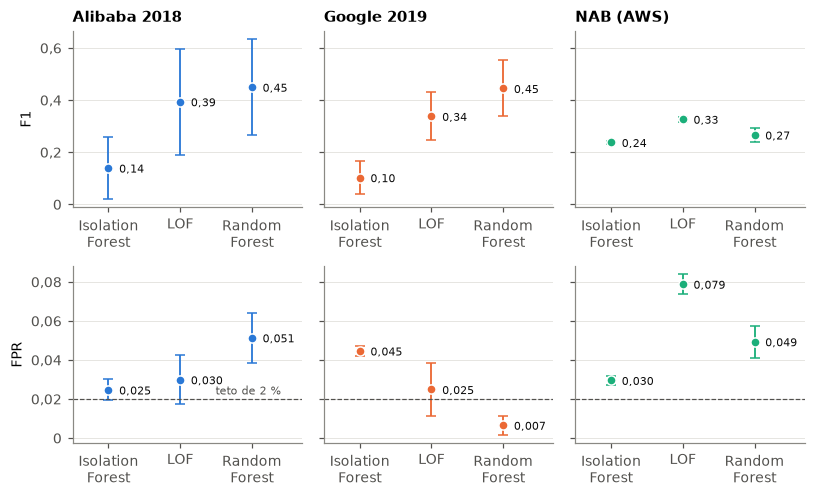

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(7.5, 4.6), sharey="row")
x = np.arange(len(MODELOS))
for j, ds in enumerate(DATASETS):
    c = comp[comp["dataset"] == ds].set_index("modelo").loc[MODELOS]
    for i, (met, rotulo) in enumerate([("f1", "F1"), ("fpr", "FPR")]):
        ax = axes[i, j]
        ax.errorbar(x, c[f"{met}_mean"], yerr=c[f"{met}_std"], fmt="o", color=COR[ds], markersize=6,
                    capsize=3, elinewidth=1.2, markeredgecolor="white", markeredgewidth=1)
        for xi, v in zip(x, c[f"{met}_mean"]):
            ax.annotate(br(v, 2 if met == "f1" else 3), (xi, v), xytext=(7, -3), textcoords="offset points",
                        fontsize=7.5, color="#0b0b0b")
        if met == "fpr":
            ax.axhline(TETO_FPR, color=CINZA, linestyle="--", linewidth=0.8)
            if j == 0:
                ax.annotate("teto de 2 %", (x[-1] + 0.4, TETO_FPR), xytext=(0, 3), textcoords="offset points",
                            fontsize=7.5, color=CINZA, ha="right")
        ax.set_xticks(x, [NOMES[m].replace(" ", "\n") for m in MODELOS])
        ax.set_xlim(-0.5, len(MODELOS) - 0.3)
        ax.grid(axis="x", visible=False)
        if j == 0:
            ax.set_ylabel(rotulo)
        if i == 0:
            ax.set_title(NOME_DS[ds])
for ax in axes.flat:
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(round(v, 3))))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_res_f1_fpr.png")
plt.show()

## 3. As diferenças entre modelos são consistentes?

Teste de Friedman (os três modelos, pareados por repetição) e Wilcoxon pareado entre cada par, com correção de Holm,
sobre o F1 das 30 repetições. As repetições compartilham a mesma série-base e só mudam as anomalias injetadas,
então os p-valores indicam consistência dentro deste desenho experimental, não generalização para outros clusters.

In [5]:
def holm(p):
    p = np.asarray(p, dtype=float)
    ordem = np.argsort(p)
    ajust = np.empty_like(p)
    acum = 0.0
    for k, i in enumerate(ordem):
        acum = max(acum, min(1.0, (len(p) - k) * p[i]))
        ajust[i] = acum
    return ajust


linhas = []
for ds in DATASETS:
    f1 = completo[completo["dataset"] == ds].pivot(index="repeticao", columns="modelo", values="f1")[MODELOS]
    _, p_friedman = stats.friedmanchisquare(*[f1[m] for m in MODELOS])
    pares = [("isolation_forest", "lof"), ("isolation_forest", "random_forest"), ("lof", "random_forest")]
    brutos = []
    for a, b in pares:
        dif = f1[a] - f1[b]
        brutos.append(1.0 if np.allclose(dif, 0) else stats.wilcoxon(f1[a], f1[b]).pvalue)
    for (a, b), p, pa in zip(pares, brutos, holm(brutos)):
        linhas.append({"dataset": NOME_DS[ds], "p_friedman": p_friedman, "comparação": f"{NOMES[a]} × {NOMES[b]}",
                       "diferença média de F1": (f1[a] - f1[b]).mean(), "p_wilcoxon_holm": pa,
                       "vitórias do 1º": int((f1[a] > f1[b]).sum()), "vitórias do 2º": int((f1[b] > f1[a]).sum())})
testes = pd.DataFrame(linhas)
testes.to_csv(TAB_DIR / "tab_res_testes_estatisticos.csv", index=False)
testes.style.format({"p_friedman": "{:.2e}", "p_wilcoxon_holm": "{:.2e}", "diferença média de F1": "{:+.3f}"})

,dataset,p_friedman,comparação,diferença média de F1,p_wilcoxon_holm,vitórias do 1º,vitórias do 2º
0,Alibaba 2018,9.59e-09,Isolation Forest × LOF,-0.254,1.45e-05,3,26
1,Alibaba 2018,9.59e-09,Isolation Forest × Random Forest,-0.310,5.59e-09,0,30
2,Alibaba 2018,9.59e-09,LOF × Random Forest,-0.056,1.24e-01,12,18
3,Google 2019,1.14e-11,Isolation Forest × LOF,-0.235,5.59e-09,0,30
4,Google 2019,1.14e-11,Isolation Forest × Random Forest,-0.342,5.59e-09,0,30
5,Google 2019,1.14e-11,LOF × Random Forest,-0.107,6.29e-05,6,24
6,NAB (AWS),3.00e-12,Isolation Forest × LOF,-0.089,5.59e-09,0,30
7,NAB (AWS),3.00e-12,Isolation Forest × Random Forest,-0.029,9.22e-06,4,26
8,NAB (AWS),3.00e-12,LOF × Random Forest,+0.060,5.59e-09,30,0


## 4. Validação cruzada × teste

Média de F1 e FPR da combinação escolhida na validação cruzada (treino da repetição 0) ao lado da média no teste
(30 repetições). Uma queda grande indica que o teste difere do treino — por exemplo, pela deriva vista no
pré-processamento.

In [6]:
linhas = []
for ds in DATASETS:
    cv = pd.read_csv(EXP / f"gridsearch_{ds}.csv")
    for m in MODELOS:
        esc = cv[(cv["modelo"] == m) & cv["escolhida"]].iloc[0]
        t = comp[(comp["dataset"] == ds) & (comp["modelo"] == m)].iloc[0]
        linhas.append({"dataset": NOME_DS[ds], "modelo": NOMES[m],
                       "F1 validação": esc["mean_test_f1"], "F1 teste": t["f1_mean"],
                       "FPR validação": esc["mean_test_fpr"], "FPR teste": t["fpr_mean"]})
val_teste = pd.DataFrame(linhas)
val_teste.to_csv(TAB_DIR / "tab_res_validacao_vs_teste.csv", index=False)
val_teste.round(4)

,dataset,modelo,F1 validação,F1 teste,FPR validação,FPR teste
0,Alibaba 2018,Isolation Forest,0.2920,0.1398,0.0149,0.0247
1,Alibaba 2018,LOF,0.4303,0.3943,0.0170,0.0299
2,Alibaba 2018,Random Forest,0.5067,0.4501,0.0186,0.0514
3,Google 2019,Isolation Forest,0.0543,0.1030,0.0172,0.0447
4,Google 2019,LOF,0.2571,0.3381,0.0323,0.0249
5,Google 2019,Random Forest,0.5073,0.4451,0.0022,0.0066
6,NAB (AWS),Isolation Forest,0.0890,0.2380,0.0683,0.0296
7,NAB (AWS),LOF,0.1044,0.3270,0.1623,0.0789
8,NAB (AWS),Random Forest,0.2893,0.2667,0.0176,0.0494


## 5. Recall por tipo de anomalia (Alibaba e Google)

Fração dos eventos injetados de cada tipo com pelo menos uma janela marcada, somando as 30 repetições.
Vazamento de memória e queda de CPU **não aparecem no treino**: para o Random Forest, que aprende com os rótulos
da injeção, eles medem generalização para padrões não vistos.

In [7]:
tipos = pd.concat([pd.read_csv(EXP / f"recall_por_tipo_{ds}.csv") for ds in ("alibaba", "google")])
tipos = tipos[tipos["variante"] == "completo"]
rt = tipos.groupby(["dataset", "tipo", "modelo"])[["eventos", "detectados"]].sum()
rt["recall"] = rt["detectados"] / rt["eventos"]
rt_tab = rt["recall"].unstack("modelo")[MODELOS].rename(columns=NOMES)
rt_tab["eventos"] = rt["eventos"].groupby(["dataset", "tipo"]).first()
SO_TESTE = {"vazamento_memoria", "queda_cpu"}
rt_tab["só no teste"] = [t in SO_TESTE for _, t in rt_tab.index]
rt_tab.to_csv(TAB_DIR / "tab_res_recall_por_tipo.csv")
rt_tab.round(3)

modelo                      Isolation Forest    LOF  Random Forest  eventos  só no teste
dataset tipo                                                                            
alibaba memoria_sustentada             0.714  0.810          1.000       21        False
        pico_cpu                       0.231  1.000          0.615       13        False
        queda_cpu                      0.250  0.812          0.250       16         True
        rajada_rede                    1.000  1.000          0.947       19        False
        vazamento_memoria              0.591  0.636          1.000       22         True
google  memoria_sustentada             0.125  0.469          0.875       64        False
        pico_cpu                       0.400  0.938          0.877       65        False
        queda_cpu                      0.557  0.967          0.033       61         True
        vazamento_memoria              0.221  0.529          0.794       68         True

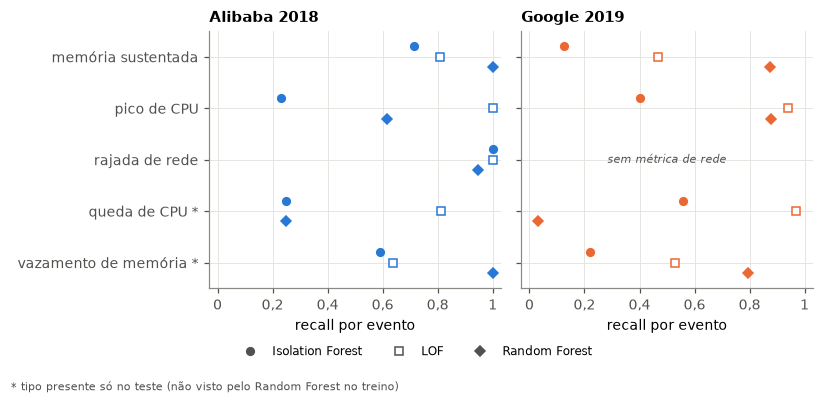

In [8]:
TIPOS_ORDEM = ["memoria_sustentada", "pico_cpu", "rajada_rede", "queda_cpu", "vazamento_memoria"]
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2), sharey=True)
marcadores = {"isolation_forest": "o", "lof": "s", "random_forest": "D"}
y = np.arange(len(TIPOS_ORDEM))
for ax, ds in zip(axes, ("alibaba", "google")):
    d = rt_tab.loc[ds].reindex(TIPOS_ORDEM)
    for k, m in enumerate(MODELOS):
        ax.plot(d[NOMES[m]], y + (k - 1) * 0.2, linestyle="none", marker=marcadores[m], markersize=5,
                color=COR[ds], markerfacecolor="white" if m == "lof" else COR[ds], label=NOMES[m])
    if ds == "google":
        ax.text(0.5, TIPOS_ORDEM.index("rajada_rede"), "sem métrica de rede", ha="center", va="center",
                fontsize=7.5, color=CINZA, style="italic")
    ax.set_xlim(-0.03, 1.03)
    ax.set_title(NOME_DS[ds])
    ax.set_xlabel("recall por evento")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: br(round(v, 2))))
axes[0].set_yticks(y, [ROTULOS_TIPO[t] + (" *" if t in SO_TESTE else "") for t in TIPOS_ORDEM])
axes[0].set_ylim(len(TIPOS_ORDEM) - 0.5, -0.5)
alcas = [plt.Line2D([], [], linestyle="none", marker=marcadores[m], markersize=5, color=CINZA,
                    markerfacecolor="white" if m == "lof" else CINZA) for m in MODELOS]
fig.legend(alcas, [NOMES[m] for m in MODELOS], loc="lower center", ncols=3, frameon=False, fontsize=8,
           bbox_to_anchor=(0.5, -0.06))
fig.text(0.01, -0.12, "* tipo presente só no teste (não visto pelo Random Forest no treino)", fontsize=7.5, color=CINZA)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_res_recall_por_tipo.png")
plt.show()

## 6. Efeito do contexto horário (ablação)

Mesmos hiperparâmetros, com e sem seno/cosseno da hora. Diferença = com contexto − sem contexto, pareada por
repetição; p-valor do teste de Wilcoxon pareado.

In [9]:
linhas = []
for (ds, m), g in res.groupby(["dataset", "modelo"]):
    piv = {met: g.pivot(index="repeticao", columns="variante", values=met) for met in ("f1", "fpr")}
    dif_f1 = piv["f1"]["completo"] - piv["f1"]["sem_contexto"]
    dif_fpr = piv["fpr"]["completo"] - piv["fpr"]["sem_contexto"]
    p = 1.0 if np.allclose(dif_f1, 0) else stats.wilcoxon(piv["f1"]["completo"], piv["f1"]["sem_contexto"]).pvalue
    linhas.append({"dataset": NOME_DS[ds], "modelo": NOMES[m],
                   "F1 com hora": piv["f1"]["completo"].mean(), "F1 sem hora": piv["f1"]["sem_contexto"].mean(),
                   "ΔF1": dif_f1.mean(), "p_wilcoxon": p,
                   "FPR com hora": piv["fpr"]["completo"].mean(), "FPR sem hora": piv["fpr"]["sem_contexto"].mean(),
                   "ΔFPR": dif_fpr.mean()})
ablacao = pd.DataFrame(linhas)
ablacao.to_csv(TAB_DIR / "tab_res_ablacao_contexto.csv", index=False)
ablacao.style.format({c: "{:.3f}" for c in ablacao.columns if c not in ("dataset", "modelo", "p_wilcoxon")}
                     | {"p_wilcoxon": "{:.2e}", "ΔF1": "{:+.3f}", "ΔFPR": "{:+.4f}"})

,dataset,modelo,F1 com hora,F1 sem hora,ΔF1,p_wilcoxon,FPR com hora,FPR sem hora,ΔFPR
0,Alibaba 2018,Isolation Forest,0.140,0.126,+0.014,7.92e-01,0.025,0.014,+0.0107
1,Alibaba 2018,LOF,0.394,0.358,+0.036,4.90e-01,0.030,0.006,+0.0241
2,Alibaba 2018,Random Forest,0.450,0.436,+0.014,4.04e-02,0.051,0.062,-0.0102
3,Google 2019,Isolation Forest,0.103,0.127,-0.024,3.48e-03,0.045,0.050,-0.0053
4,Google 2019,LOF,0.338,0.300,+0.038,1.13e-02,0.025,0.019,+0.0059
5,Google 2019,Random Forest,0.445,0.435,+0.010,4.69e-01,0.007,0.006,+0.0006
6,NAB (AWS),Isolation Forest,0.238,0.232,+0.006,2.37e-05,0.030,0.030,-0.0002
7,NAB (AWS),LOF,0.327,0.329,-0.002,3.09e-01,0.079,0.081,-0.0018
8,NAB (AWS),Random Forest,0.267,0.272,-0.005,3.49e-01,0.049,0.075,-0.0255


## 7. NAB: detecção por série

In [10]:
ps = pd.read_csv(EXP / "nab_por_serie.csv")
ps = ps[ps["variante"] == "completo"]
nab_serie = ps.groupby(["serie", "modelo"])[["recall", "fpr"]].mean().unstack("modelo")
nab_serie.columns = [f"{met} {NOMES[m]}" for met, m in nab_serie.columns]
nab_serie.insert(0, "janelas", ps.groupby("serie")["janelas"].first())
nab_serie.to_csv(TAB_DIR / "tab_res_nab_por_serie.csv")
nab_serie.round(3)

,janelas,recall Isolation Forest,recall LOF,recall Random Forest,fpr Isolation Forest,fpr LOF,fpr Random Forest
serie,,,,,,,
cpu_utilization_asg_misconfiguration,1,1.000,1.000,1.000,0.015,0.011,0.017
ec2_cpu_utilization_24ae8d,2,1.000,0.967,1.000,0.006,0.007,0.001
ec2_cpu_utilization_53ea38,2,1.000,1.000,0.733,0.012,0.010,0.021
ec2_cpu_utilization_5f5533,2,0.833,0.900,0.650,0.001,0.051,0.000
ec2_cpu_utilization_77c1ca,1,1.000,1.000,0.200,0.019,0.020,0.000
ec2_cpu_utilization_825cc2,1,1.000,1.000,0.700,0.021,0.024,0.004
ec2_cpu_utilization_ac20cd,1,1.000,1.000,1.000,0.000,0.001,0.075
ec2_cpu_utilization_c6585a,0,0.000,0.000,0.000,0.005,0.007,0.000
ec2_cpu_utilization_fe7f93,3,0.667,0.667,0.700,0.042,0.070,0.142


### Caso com causa conhecida: falha documentada da API da AWS

Série `ec2_request_latency_system_failure` (grupo `realKnownCause`), repetição 0: o que cada modelo marcou no
trecho de teste. As faixas cinza são as janelas oficiais do NAB.

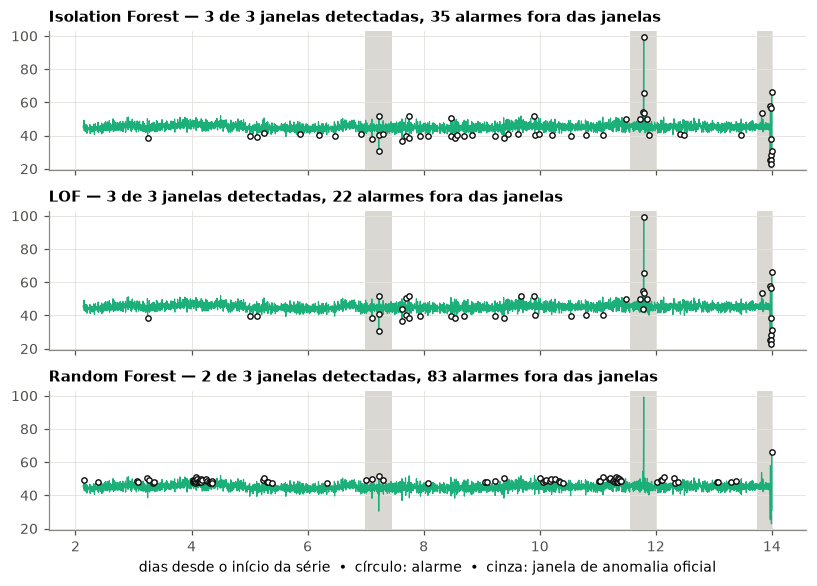

,modelo,janelas,janelas_detectadas,alarmes,alarmes_em_janela,pontos_fora,alarmes_fora
0,Isolation Forest,3,3,57,22,3072,35
1,LOF,3,3,43,21,3072,22
2,Random Forest,3,2,88,5,3072,83


In [11]:
CASO = "ec2_request_latency_system_failure"
tab_nab, _ = preparar_nab(0)
g = tab_nab[tab_nab["serie"] == CASO]
cols = [c for c in g.columns if c not in {"treino", "rotulo", "tipo_anomalia", "evento_id", "excluir", "serie"}]
bruto = data.load_nab("realKnownCause/" + CASO + ".csv")
tr, te = g[g["treino"]], g[~g["treino"]]

fig, axes = plt.subplots(len(MODELOS), 1, figsize=(7.5, 5.4), sharex=True)
dias = (te.index - bruto.index[0]) / pd.Timedelta(days=1)
caso_linhas = []
for ax, m in zip(axes, MODELOS):
    pipe = pipeline(m, execucao["melhores_parametros"]["nab"][m]).fit(tr[cols], tr["rotulo"])
    p = pipe.predict(te[cols])
    c = contagens_por_evento(te["evento_id"], p)
    caso_linhas.append({"modelo": NOMES[m], **c})
    for k in sorted(set(te["evento_id"]) - {0}):
        dentro = dias[te["evento_id"] == k]
        ax.axvspan(dentro.min(), dentro.max(), color=DESTAQUE, linewidth=0, zorder=0)
    ax.plot(dias, bruto.loc[te.index, "value"], color=COR["nab"], linewidth=0.8)
    ax.plot(dias[p == 1], bruto.loc[te.index[p == 1], "value"], linestyle="none", marker="o", markersize=3.5,
            markerfacecolor="white", markeredgecolor="#0b0b0b", markeredgewidth=0.9)
    ax.set_title(f"{NOMES[m]} — {c['janelas_detectadas']} de {c['janelas']} janelas detectadas, "
                 f"{c['alarmes_fora']} alarmes fora das janelas")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v)))
axes[-1].set_xlabel("dias desde o início da série  •  círculo: alarme  •  cinza: janela de anomalia oficial")
axes[-1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: br(round(v, 1))))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_res_nab_falha_api_aws.png")
plt.show()
caso_aws = pd.DataFrame(caso_linhas)
caso_aws.to_csv(TAB_DIR / "tab_res_nab_caso_aws.csv", index=False)
caso_aws

## 8. Janelas de cobertura baixa (Alibaba)

As 4 janelas com menos de 2 mil máquinas reportando ficam fora do treino e das métricas. Depois do treino, cada
modelo as classifica; a tabela mostra quantas, em média, foram marcadas como anomalia.

In [12]:
ali = res[(res["dataset"] == "alibaba")]
sinal = ali.groupby(["variante", "modelo"])[["sinalizadas", "sinalizadas_marcadas"]].mean().reset_index()
sinal["modelo"] = sinal["modelo"].map(NOMES)
sinal.to_csv(TAB_DIR / "tab_res_cobertura_baixa.csv", index=False)
sinal

,variante,modelo,sinalizadas,sinalizadas_marcadas
0,completo,Isolation Forest,4.0,1.100000
1,completo,LOF,4.0,0.000000
2,completo,Random Forest,4.0,0.000000
3,sem_contexto,Isolation Forest,4.0,0.766667
4,sem_contexto,LOF,4.0,0.733333
5,sem_contexto,Random Forest,4.0,0.000000


## 9. Estudo de caso: rajadas de tarefas com falha (Alibaba)

Proxy definido pelo autor na EDA (seção 6.3): trechos em que a média móvel de 1 h de tarefas `Failed` passa de
20 vezes a mediana. Os escores vêm de validação cruzada por blocos de 1 dia (cada dia é pontuado por um modelo
treinado nos outros dias, sem as rajadas e sem as janelas de cobertura baixa), com os hiperparâmetros do Alibaba e
sem injeção. Se as rajadas fossem visíveis nas métricas, seriam marcadas com mais frequência que o resto e a AUC
do escore ficaria acima de 0,5.

In [13]:
escores = cs.escores_fora_da_amostra(cs.parametros_alibaba())
caso_rajadas = cs.resumo(escores)
caso_rajadas["modelo"] = caso_rajadas["modelo"].map(NOMES)
caso_rajadas.to_csv(TAB_DIR / "tab_res_estudo_caso_rajadas.csv", index=False)
print("Rajadas:", cs.rajadas(cs.falhas_por_janela()))
caso_rajadas.round(3)

Rajadas: [(506, 523), (783, 842), (1108, 1108), (1110, 1127), (1927, 1945), (1954, 1988)]


,modelo,janelas_em_rajada,marcadas_em_rajada,marcadas_fora,auc_escore
0,Isolation Forest,133,0.000,0.026,0.337
1,LOF,133,0.008,0.052,0.502


In [14]:
cob = escores[escores["cobertura_baixa"]].groupby("modelo")["anomalia"].agg(["size", "sum"])
cob.index = cob.index.map(NOMES)
cob.columns = ["janelas de cobertura baixa", "marcadas (fora da amostra)"]
cob

,janelas de cobertura baixa,marcadas (fora da amostra)
modelo,,
Isolation Forest,4,3
LOF,4,3


## 10. Síntese

**Não há vencedor único.** O melhor modelo muda conforme o dataset e o tipo de anomalia:

- **Anomalias sintéticas (Alibaba e Google):** o Random Forest tem o maior F1 (0,45 nos dois). No Alibaba, a
  diferença para o LOF (0,39) não é estatisticamente significativa (Wilcoxon com Holm, p = 0,12); no Google, é
  (0,45 × 0,34). O Isolation Forest fica muito abaixo (0,14 e 0,10).
- **Anomalias reais (NAB):** o LOF tem o maior F1 por evento (0,33 contra 0,27 do Random Forest e 0,24 do Isolation
  Forest, com diferenças significativas), mas também a maior FPR (7,9 %). Quase metade dos alarmes falsos do LOF vem
  de uma única série (`rds_cpu_utilization_e47b3b`), que muda de patamar depois do período de treino; sem ela, a
  FPR do LOF cai para 4,2 %. O Isolation Forest tem a menor FPR no NAB (3,0 %), com revocação por evento de 0,88.
- **Generalização do Random Forest:** ele detecta bem o vazamento de memória, que não viu no treino mas desvia no
  mesmo sentido das anomalias de treino (revocação 1,00 e 0,79), e falha nas quedas de CPU (0,25 e 0,03), que
  desviam no sentido oposto. O LOF detecta as quedas (0,81 e 0,97): o detector supervisionado aprende a "forma"
  das anomalias injetadas; o de densidade reage a qualquer desvio.
- **Teto de FPR:** a regra garante FPR ≤ 2 % na validação (quando alguma combinação atinge o teto), mas no teste
  a FPR sobe na maioria dos casos (2,5 % a 5,1 % no Alibaba). A causa é a deriva entre períodos — por exemplo, a
  memória do Alibaba no teste está 0,58 desvio padrão acima do treino. A FPR medida na validação subestima a de
  produção; retreinamento periódico é necessário.
- **Contexto horário:** efeito pequeno e inconsistente (ΔF1 entre −0,02 e +0,04); no Alibaba, aumentou a FPR do
  LOF de 0,6 % para 3,0 %. A hipótese da EDA só se confirmou parcialmente.
- **Estudo de caso:** as rajadas de falha do Alibaba são marcadas *menos* que o resto (AUC 0,34 e 0,50) —
  invisíveis nas métricas agregadas, o que confirma a decisão de não usá-las como rótulo. As janelas de cobertura
  baixa têm valores dentro da faixa normal: no protocolo principal quase não são marcadas; na validação por dias,
  IF e LOF marcam 3 de 4. Cobertura de telemetria deve ser monitorada diretamente.
- **Custo:** todos treinam em menos de 1 s e inferem em menos de 0,04 ms por amostra; custo não diferencia os
  modelos nesta escala.